In [1]:
!pip install -q ultralytics roboflow

In [2]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU disponível!")
    print("Modelo:", torch.cuda.get_device_name(0))
else:
    print("GPU não encontrada. Confira as configurações do Colab.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.215
GPU disponível!
Modelo: Tesla T4


In [3]:
from google.colab import userdata

API_KEY = userdata.get("ROBOFLOW_API_KEY")

print("Chave carregada:", API_KEY is not None)

Chave carregada: True


In [4]:
from roboflow import Roboflow

rf = Roboflow(api_key=API_KEY)

workspace = rf.workspace("gs-ykiiq")
print("Workspace conectado!")

loading Roboflow workspace...
Workspace conectado!


In [5]:
from roboflow import Roboflow
rf = Roboflow(api_key=API_KEY)
project = rf.workspace("gs-ykiiq").project("buslight-ca7ef")
version = project.version(3)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to BusLight-3 in yolov8:: 100%|██████████| 16603/16603 [00:09<00:00, 1735.54it/s]


In [6]:
DATASET_DIR = dataset.location

print("Dataset baixado em:", DATASET_DIR)

Dataset baixado em: /content/BusLight-3


In [8]:
import os

for pasta, subpastas, arquivos in os.walk(DATASET_DIR):
    nivel = pasta.replace(DATASET_DIR, "").count(os.sep)

    if nivel <= 2:
        print("  " * nivel + os.path.basename(pasta) + "/")

        for arquivo in arquivos[:5]:
            print("  " * (nivel + 1) + arquivo)

BusLight-3/
  data.yaml
  README.dataset.txt
  README.roboflow.txt
  train/
    images/
      340_jpg.rf.b1f5fb0091a3740a3bed110851334a13.jpg
      549_jpg.rf.29c56b43f7e2f052c3071ffdb251c3ef.jpg
      ia_100000876_jpg.rf.06dfed8de4a7224516a5a09b84e50ed3.jpg
      PennPed00049_png.rf.62a695dec0b8787c4da5c5a0e1bb3b09.jpg
      image_226_jpg.rf.717c775c825d79d9aec5234701e33535.jpg
    labels/
      28420_jpg.rf.364f1bb0de04f0465b19b305cc02aacc.txt
      img00000000160_jpg.rf.f9a5955efe8de4c3cdfb61282f54eaee.txt
      9_png_jpg.rf.287424109c16ef88a6f7e99e0e3ddaf0.txt
      1892_jpg.rf.9e48d73eab8eb7934257753ff9c060ad.txt
      20230501_171401_jpg.rf.38b478db942ced39ae273d99c9cabf55.txt
  test/
    images/
      -1209367746_jpg.rf.6fefbdbbcff9dd6b871aafada7d1c565.jpg
      20230501_232732_jpg.rf.5b24d4a6a45e38e52bbc54215421913b.jpg
      ia_300000332_jpg.rf.805ce1004744f7720f25096847173e13.jpg
      Screenshot-from-2023-05-18-23-23-25_png.rf.ad99ee864f00311f167a0c8665373bb6.jpg
      ia_10

In [9]:
import yaml

DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")

with open(DATA_YAML, "r") as arquivo:
    config = yaml.safe_load(arquivo)

print("Classes encontradas:")

for identificador, nome in enumerate(config["names"]):
    print(identificador, ":", nome)

Classes encontradas:
0 : Bus
1 : Person
2 : walking-frame
3 : wheelchair
4 : wheelchairs


In [10]:
for divisao in ["train", "valid", "test"]:

    caminho = os.path.join(DATASET_DIR, divisao, "images")

    if os.path.exists(caminho):
        quantidade = len([
            arquivo for arquivo in os.listdir(caminho)
            if arquivo.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ])

        print(f"{divisao}: {quantidade} imagens")
    else:
        print(f"{divisao}: pasta não encontrada")

train: 5816 imagens
valid: 1656 imagens
test: 827 imagens


In [11]:
from ultralytics import YOLO

# Carregar modelo pré-treinado
model = YOLO("yolo11n.pt")

print("Modelo carregado!")

Modelo carregado!


In [16]:
results = model.train(
    data=DATA_YAML,
    epochs=60,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=15,
    project="/content/BusLight/resultados",
    name="treinamento_yolo",
    plots=True,
    save=True,
    verbose=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BusLight-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/BusLight/resultados/treinamento_yolo/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=treiname

In [17]:
BEST_MODEL = "/content/BusLight/resultados/treinamento_yolo/weights/best.pt"

print("Modelo encontrado:", os.path.exists(BEST_MODEL))

Modelo encontrado: True


In [18]:
best_model = YOLO(BEST_MODEL)

metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1938.0±1868.1 MB/s, size: 285.3 KB)
val: Scanning /content/BusLight-3/test/labels.cache... 827 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 827/827 315.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 8.9it/s 11.7s
                   all        827       1163      0.835       0.83      0.878      0.678
                   Bus        307        454      0.908      0.737      0.845      0.657
                Person         25        127      0.643      0.512      0.586      0.344
         walking-frame          7          9       0.83          1      0.995      0.837
            wheelchair          6          6       0.86          1      0.995      0.892
           wheelchairs        487    

In [20]:
print("RESULTADOS DA AVALIAÇÃO")
print("-----------------------")

print("Precisão (Precision):", metrics.box.mp)
print("Revocação (Recall):", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

RESULTADOS DA AVALIAÇÃO
-----------------------
Precisão (Precision): 0.835078736279127
Revocação (Recall): 0.8297572216479772
mAP50: 0.8781716377893515
mAP50-95: 0.6777590187944758


In [21]:
from google.colab import files

uploaded = files.upload()

imagem_teste = next(iter(uploaded.keys()))

resultados = best_model.predict(
    source=imagem_teste,
    conf=0.25,
    save=True,
    imgsz=640
)

Saving pexels-henry-acevedo-382866382-31876101.jpg to pexels-henry-acevedo-382866382-31876101.jpg

image 1/1 /content/pexels-henry-acevedo-382866382-31876101.jpg: 640x448 6 Persons, 1 wheelchairs, 8.1ms
Speed: 2.6ms preprocess, 8.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 448)
Results saved to /content/runs/detect/predict


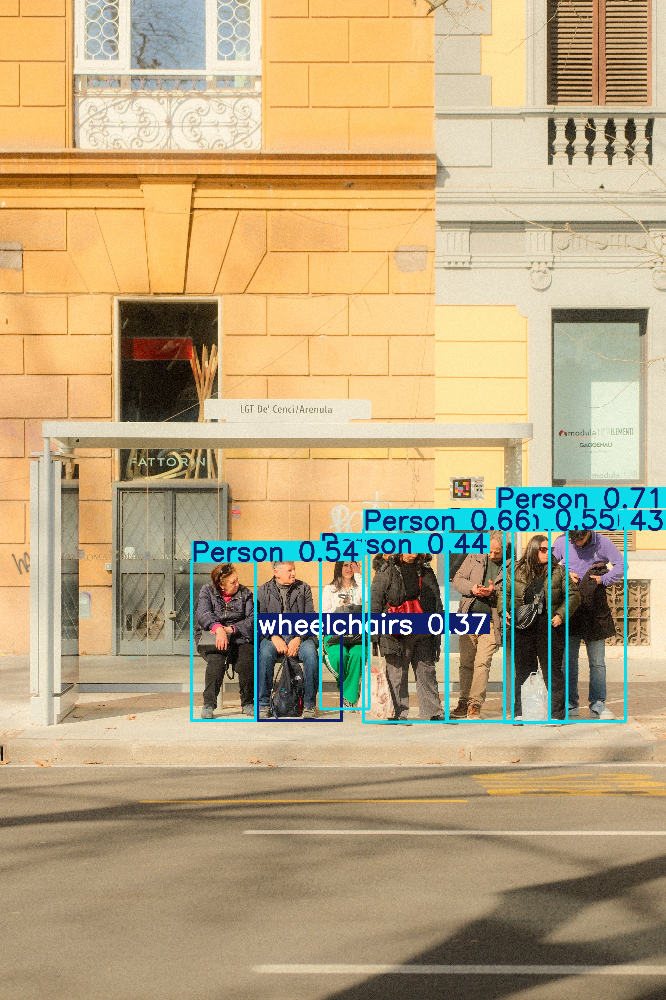

In [22]:
from IPython.display import display
from PIL import Image

imagem_resultado = resultados[0].plot()

display(Image.fromarray(imagem_resultado[..., ::-1]))

In [23]:
for pasta, subpastas, arquivos in os.walk(
    "/content/BusLight/resultados/treinamento_yolo"
):
    for arquivo in arquivos:
        if "confusion_matrix" in arquivo:
            print(os.path.join(pasta, arquivo))

/content/BusLight/resultados/treinamento_yolo/confusion_matrix.png
/content/BusLight/resultados/treinamento_yolo/confusion_matrix_normalized.png


In [24]:
from google.colab import files

files.download(BEST_MODEL)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 confusion_matrix.png


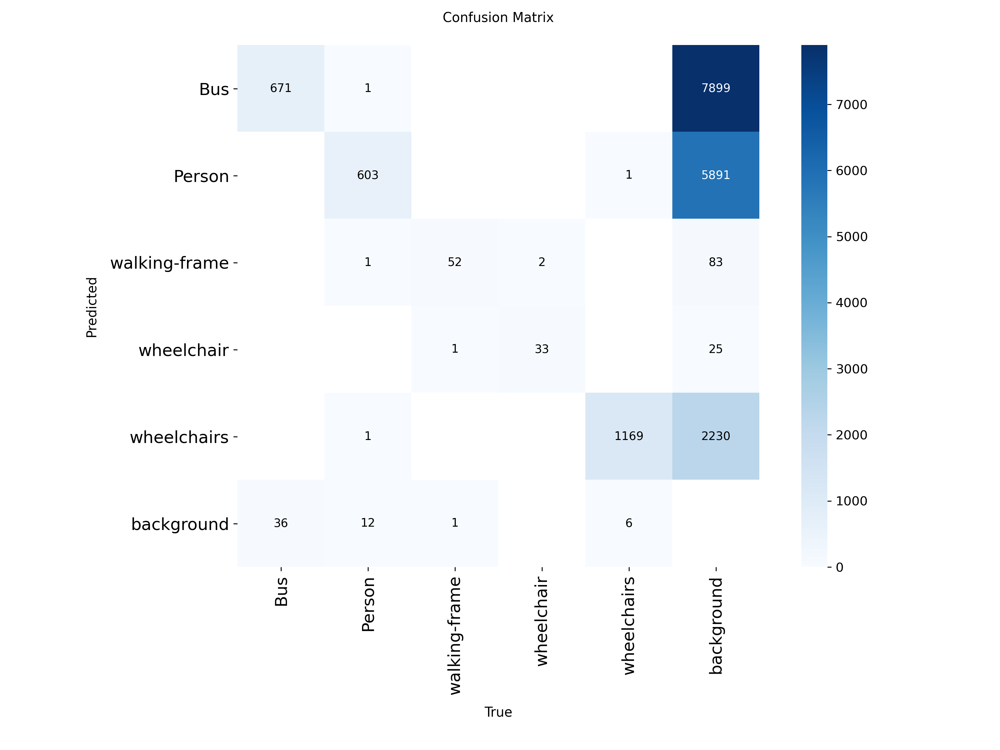


 confusion_matrix_normalized.png


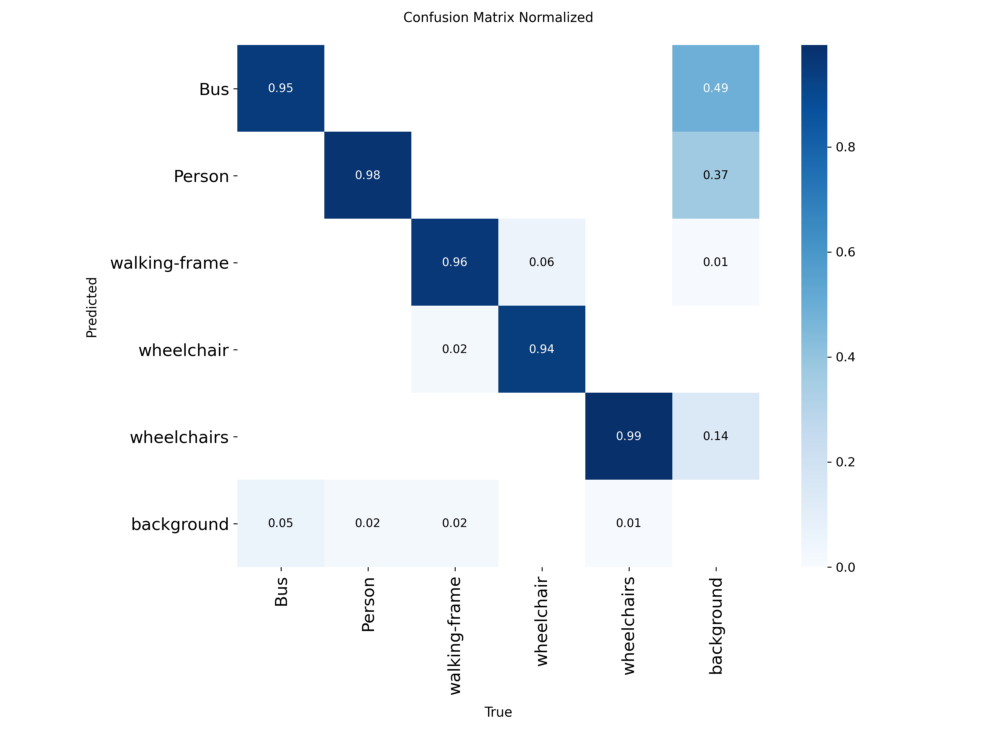

In [25]:
from IPython.display import display, Image

pasta = str(results.save_dir)

arquivos = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

for nome in arquivos:
    caminho = os.path.join(pasta, nome)

    if os.path.exists(caminho):
        print("\n", nome)
        display(Image(filename=caminho))
    else:
        print(nome, "não encontrado")

In [26]:
from ultralytics import YOLO

CAMINHO_MODELO = "/content/BusLight/resultados/treinamento_yolo-2/weights/best.pt"

model = YOLO(CAMINHO_MODELO)

print("Modelo carregado com sucesso!")
print("Classes:", model.names)
print("Caminho:", CAMINHO_MODELO)

Modelo carregado com sucesso!
Classes: {0: 'Bus', 1: 'Person', 2: 'walking-frame', 3: 'wheelchair', 4: 'wheelchairs'}
Caminho: /content/BusLight/resultados/treinamento_yolo-2/weights/best.pt


Saving Asqd_R2_2R5JEDn9tKIyViNdYamq_5hzfr-JtTdoeQzVmKk7RIH1HMiAsugCZyrK7vESwp588R9gZTpSgDCFjp1l4pjj-rrEOlsRWcqUrWnQOEW4TrXbvL3U8Gkp4fz_nyVeCj1hOOkimTGMGO6mH3P1b0GryWHT6O_y9ih2N2G3G8wVkmvYYLb8cuqmqg8y.jpg to Asqd_R2_2R5JEDn9tKIyViNdYamq_5hzfr-JtTdoeQzVmKk7RIH1HMiAsugCZyrK7vESwp588R9gZTpSgDCFjp1l4pjj-rrEOlsRWcqUrWnQOEW4TrXbvL3U8Gkp4fz_nyVeCj1hOOkimTGMGO6mH3P1b0GryWHT6O_y9ih2N2G3G8wVkmvYYLb8cuqmqg8y.jpg
Results saved to /content/runs/detect/predict-2


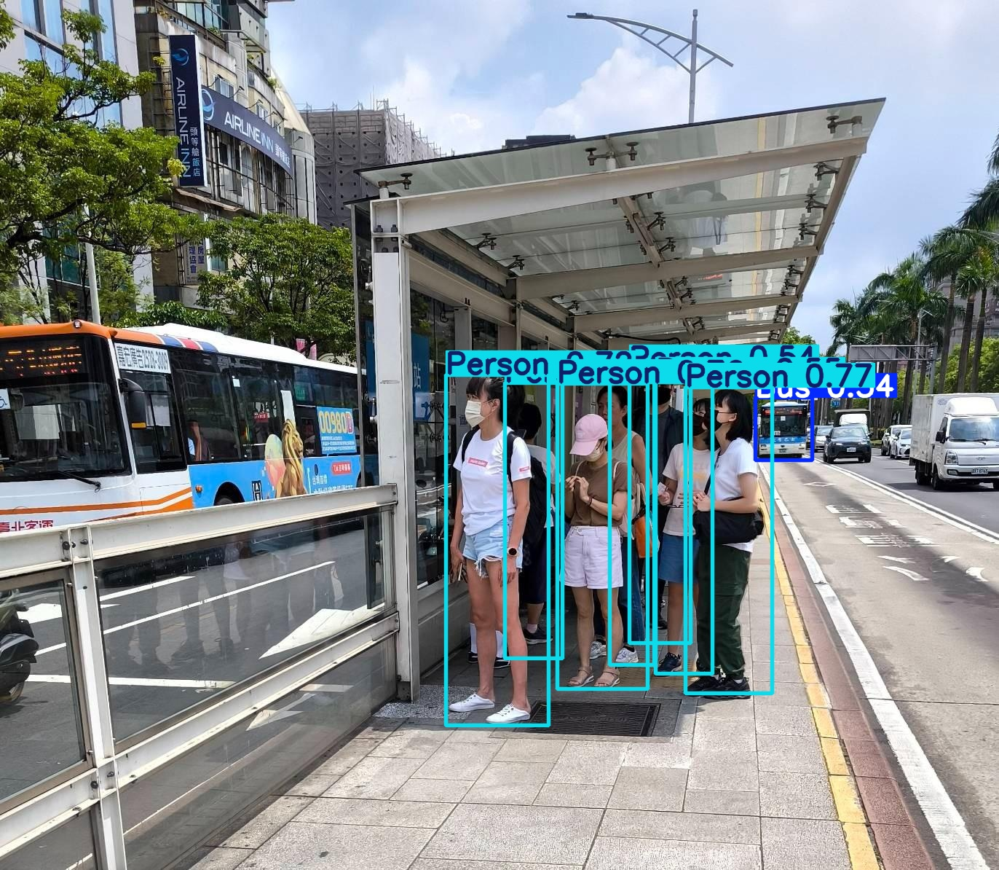


DETECÇÕES DO PONTO VIVO
Person: 7
Bus: 1

Total de objetos: 8


In [27]:
from google.colab import files
from IPython.display import display, Image

# Enviar uma imagem do computador
arquivos = files.upload()

IMAGEM = next(iter(arquivos))

# Executar detecção
resultado = model.predict(
    source=IMAGEM,
    conf=0.25,
    iou=0.7,
    save=True,
    verbose=False
)[0]

# Mostrar imagem com detecções
display(Image(filename=resultado.save_dir + "/" + os.path.basename(IMAGEM)))

# Mostrar informações
print("\nDETECÇÕES DO PONTO VIVO")

contagem = {}

for caixa in resultado.boxes:
    classe = int(caixa.cls[0])
    nome = model.names[classe]

    contagem[nome] = contagem.get(nome, 0) + 1

for nome, quantidade in contagem.items():
    print(f"{nome}: {quantidade}")

print("\nTotal de objetos:", len(resultado.boxes))

In [28]:
import ultralytics
import cv2

print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("Modelo encontrado:", os.path.exists(CAMINHO_MODELO))

Ultralytics: 8.4.215
OpenCV: 4.14.0
Modelo encontrado: True


In [38]:
from google.colab import files

arquivos = files.upload()

VIDEO = next(iter(arquivos))

print("Vídeo carregado:", VIDEO)

Saving 16606194_1920_1080_60fps.mp4 to 16606194_1920_1080_60fps.mp4
Vídeo carregado: 16606194_1920_1080_60fps.mp4


In [ ]:
from IPython.display import display, Video
import os

# Executar o rastreamento
resultados = model.track(
    source=VIDEO,
    tracker="bytetrack.yaml",
    conf=0.25,
    iou=0.7,
    persist=True,
    save=True,
    show=False,
    verbose=False
)

print("Rastreamento concluído!")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs



In [32]:
import glob

videos_salvos = glob.glob(
    "/content/runs/detect/track*/"
    "*.avi"
) + glob.glob(
    "/content/runs/detect/track*/"
    "*.mp4"
)

print("Vídeos encontrados:", videos_salvos)

Vídeos encontrados: ['/content/runs/detect/track/11916524_1920_1080_60fps.avi']
